# Défi 1 : prédiction de la bactériémie avec un réseau de neurones (PyTorch)

**Contexte :** 11 753 patients avec suspicion de bactériémie, chez qui une hémoculture a été réalisée à l'Hôpital général de Vienne (2006-2010).

**Objectif :** prédire si l'hémoculture d'un patient sera positive (**1 = bactériémie**) ou négative (**0**) à partir de 51 variables (âge, sexe, analyses de sang). Ici on utilise un réseau de neurones fait avec PyTorch.

importer `bacteriemie.csv.gz` et `bacteriemie_test.csv.gz` 

Plan :
1. découverte des données
2. nettoyage
3. séparation apprentissage / test
4. le réseau de neurones
5. valeurs manquantes et choix du scaler
6. réglage des hyperparamètres
7. choix du seuil et évaluation et matrice de confusion
8. réseau final et prédiction du fichier de test

In [1]:
import pandas as pd
import numpy as np

fichier_donnees = "bacteriemie.csv.gz"         #données d'apprentissage
fichier_test = "bacteriemie_test.csv.gz"       #fichier à prédire
fichier_sortie = "groupe4_ABAKAR_ASAS_SAAD_SOYLU_BOUGHANEM_MOUYANSELE_pytorch.csv"     #fichier de prédictions

## 1. découverte des données
On regarde à quoi ressemblent les données :
* dimensions du tableau (nombre de patients et de variables)
* types des colonnes
* répartition de la cible (combien de bactériémies)
* valeurs manquantes
* résumé statistique de quelques variables (pour repérer des valeurs aberrantes)

In [2]:
df = pd.read_csv(fichier_donnees)

print("Dimensions :", df.shape)
df.head()

Dimensions : (11753, 53)


,ID,SEX,AGE,MCV,HGB,HCT,PLT,MCH,MCHC,RDW,...,BASOR,EOSR,LYMR,MONOR,NEU,NEUR,PDW,RBC,WBC,BloodCulture
0,1,2,62,99.3,11.5,35.9,307.0,31.5,31.8,19.5,...,0.413223,0.000000,1.652893,7.024793,22.0,90.909091,10.6,3.7,24.10,no
1,3,1,72,85.1,10.3,34.7,182.0,26.0,30.6,15.0,...,0.000000,0.826446,3.305785,1.652893,11.4,94.214876,11.4,3.9,12.17,no
2,5,1,46,96.3,7.4,22.8,64.0,31.2,32.4,19.7,...,0.568182,0.568182,8.522727,6.818182,14.7,83.522727,14.1,2.5,17.45,no
3,9,2,38,85.1,13.7,38.7,183.0,30.2,35.3,12.6,...,0.000000,0.000000,8.333333,4.166667,8.4,87.500000,12.2,4.4,9.86,no
4,10,1,68,104.5,15.7,46.9,144.0,34.8,33.5,13.9,...,0.000000,1.000000,22.000000,9.000000,6.8,68.000000,12.9,4.3,9.94,no


In [3]:
#types des colonnes (tout est numérique sauf BloodCulture en yes/no)
print("Types des colonnes :")
print(df.dtypes.value_counts(), "\n")

#répartition de la cible
print("Répartition de la cible :")
print(df["BloodCulture"].value_counts(), "\n")

#pourcentage de valeurs manquantes, les 10 variables les plus touchées
manquants = (100 * df.isna().mean()).sort_values(ascending=False).round(1)
print("Pourcentage de valeurs manquantes (10 variables les plus touchées) :")
print(manquants.head(10))
print("\nPatients avec au moins une valeur manquante :", round(100 * df.isna().any(axis=1).mean()), "%")

#quelques statistiques pour repérer des valeurs aberrantes
df[["AGE", "CRP", "WBC", "CK", "HCT", "POTASS"]].describe().round(2)

Types des colonnes :
float64    49
int64       3
str         1
Name: count, dtype: int64 

Répartition de la cible :
BloodCulture
no     10809
yes      944
Name: count, dtype: int64 

Pourcentage de valeurs manquantes (10 variables les plus touchées) :
PAMY    48.0
TRIG    34.5
CHOL    34.4
GLU     28.6
AMY     26.4
LIP     24.9
HS      21.0
FIB     17.6
APTT    17.5
NT      16.8
dtype: float64

Patients avec au moins une valeur manquante : 73 %


,AGE,CRP,WBC,CK,HCT,POTASS
count,11753.00,11631.00,11376.00,10092.00,11716.00,10147.00
mean,56.20,11.03,11.25,394.71,34.44,4.00
std,18.15,9.60,13.63,2394.39,6.53,0.65
min,16.00,0.00,0.00,8.00,0.00,1.92
25%,43.00,2.99,6.65,41.00,29.80,3.67
50%,58.00,8.69,9.60,80.50,34.30,3.95
75%,70.00,16.70,13.55,184.00,39.10,4.29
max,101.00,76.32,604.47,98801.00,66.60,36.62


Ce qu'on remarque :
- 11 753 patients et 53 colonnes (l'ID, les 51 variables et la cible).
- Seulement 8 % de bactériémies, donc des classes très déséquilibrées. On regardera le F1 et il faudra baisser le seuil de décision.
- 73 % des patients ont au moins une valeur manquante, on ne peut pas les supprimer. On les remplacera à l'étape 5.
- Valeurs impossibles : un hématocrite (HCT) à 0 % et un potassium à 36,6 mmol/L, on les corrige à l'étape suivante.

## 2. Nettoyage

On vérifie qu'il n'y a pas de doublons ni de valeurs négatives, puis :
 - hématocrite = 0 (13 patients) et potassium > 10 mmol/L (3 patients) sont des erreurs de saisie, on les remplace par NaN ;
 - les valeurs très élevées mais possibles (par exemple CK à 98 801) sont gardées ;
 - le nettoyage est dans une fonction pour pouvoir l'appliquer au fichier de test (étape 8).

In [4]:
def nettoyer(tableau):
    #remplace les valeurs impossibles par NaN
    tableau = tableau.copy()
    if "HCT" in tableau:
        tableau.loc[tableau["HCT"] == 0, "HCT"] = np.nan        #hématocrite à 0 %
    if "POTASS" in tableau:
        tableau.loc[tableau["POTASS"] > 10, "POTASS"] = np.nan  #potassium > 10 mmol/L
    return tableau


print("Doublons :", df.duplicated().sum(), "| valeurs négatives :", (df.drop(columns="BloodCulture") < 0).sum().sum())

df = nettoyer(df)

#cible : yes = 1, no = 0
y = (df["BloodCulture"] == "yes").astype(int)

#variables explicatives (sans l'ID et la cible)
X = df.drop(columns=["ID", "BloodCulture"])

print("Patients :", len(df), "| bactériémies :", round(100 * y.mean(), 1), "%")

Doublons : 0 | valeurs négatives : 0
Patients : 11753 | bactériémies : 8.0 %


## 3. Séparation apprentissage / test
On met 20 % des patients de côté (test interne), qui ne servent qu'à la fin pour évaluer le réseau. On a pris le même découpage que dans le script 1 (même `random_state`), comme ça les deux scripts sont évalués sur les mêmes patients et on peut les comparer.

Les réglages se font sur les 80 % restants avec une validation croisée à 5 plis.

In [5]:
from sklearn.model_selection import train_test_split, StratifiedKFold

#découpage 80 / 20, stratifié pour garder 8 % de malades de chaque côté
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

#validation croisée stratifiée à 5 plis
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Apprentissage :", len(X_train), "patients | test interne :", len(X_test), "patients")

Apprentissage : 9402 patients | test interne : 2351 patients


## 4. Le réseau de neurones
On utilise un réseau simple avec 2 couches cachées : les variables du patient passent dans une couche de `n1` neurones, puis une couche de `n2` neurones, puis une sortie qui donne un score.

- Entre les couches on met une ReLU (les valeurs négatives sont mises à 0), c'est ce qui permet au réseau d'apprendre des relations non linéaires.
- À la fin, la sigmoïde transforme le score en probabilité entre 0 et 1.
- La perte est `BCEWithLogitsLoss` (entropie croisée binaire). Le paramètre `pos_weight` permet de donner plus de poids aux malades.
- L'optimiseur est Adam avec un pas d'apprentissage de 0,001.
- Le `DataLoader` envoie les patients par mini-lots de 64, mélangés à chaque époque (une époque = un passage sur tous les patients). On fait 20 époques.
- `weight_decay` est une régularisation qui empêche les poids de devenir trop grands, pour limiter le sur-apprentissage.

On écrit 3 fonctions : la classe du réseau, une fonction pour l'entraîner et une pour prédire les probabilités. La fonction d'entraînement garde aussi la perte à chaque époque pour pouvoir tracer la courbe d'apprentissage.

In [6]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

torch.set_num_threads(1)   #pour un petit réseau c'est plus rapide avec 1 seul cœur


class Reseau(nn.Module):
    def __init__(self, n_entrees, n1=64, n2=32):
        super().__init__()
        self.couche1 = nn.Linear(n_entrees, n1)   #1re couche cachée
        self.couche2 = nn.Linear(n1, n2)          #2e couche cachée
        self.sortie = nn.Linear(n2, 1)            #sortie : 1 score
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.couche1(x))
        x = self.relu(self.couche2(x))
        return self.sortie(x)


def entrainer(X, y, n1=64, n2=32, weight_decay=0.001, pos_weight=1, epochs=20, X_val=None, y_val=None):
    #entraîne un réseau et renvoie le réseau + la perte à chaque époque
    torch.manual_seed(42)                                     #pour avoir toujours les mêmes résultats
    X = torch.FloatTensor(np.asarray(X, dtype=np.float32))    #conversion en tenseurs
    y = torch.FloatTensor(np.asarray(y, dtype=np.float32))
    chargeur = DataLoader(TensorDataset(X, y), batch_size=64, shuffle=True)   #mini-lots de 64 patients

    reseau = Reseau(X.shape[1], n1, n2)
    critere = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([float(pos_weight)]))
    optimiseur = torch.optim.Adam(reseau.parameters(), lr=0.001, weight_decay=weight_decay)

    pertes = {"entraînement": [], "validation": []}
    for epoque in range(epochs):
        reseau.train()
        for lot_X, lot_y in chargeur:
            sortie = reseau(lot_X).squeeze(1)     #prédiction
            perte = critere(sortie, lot_y)        #calcul de l'erreur
            optimiseur.zero_grad()                #remise à zéro des gradients
            perte.backward()                      #calcul des gradients
            optimiseur.step()                     #mise à jour des poids

        #perte à la fin de chaque époque (pour la courbe d'apprentissage)
        reseau.eval()
        with torch.no_grad():
            pertes["entraînement"].append(critere(reseau(X).squeeze(1), y).item())
            if X_val is not None:
                Xv = torch.FloatTensor(np.asarray(X_val, dtype=np.float32))
                yv = torch.FloatTensor(np.asarray(y_val, dtype=np.float32))
                pertes["validation"].append(critere(reseau(Xv).squeeze(1), yv).item())
    return reseau, pertes


def predire_proba(reseau, X):
    #probabilité de bactériémie pour chaque patient
    reseau.eval()
    with torch.no_grad():
        X = torch.FloatTensor(np.asarray(X, dtype=np.float32))
        return torch.sigmoid(reseau(X)).squeeze(1).numpy()   #la sigmoïde donne une probabilité

## 5. Valeurs manquantes et choix du scaler
Contrairement aux modèles à base d'arbres, un réseau de neurones ne peut pas gérer les NaN et il est très sensible à l'échelle des variables (la CK monte à 98 801 alors que le calcium ne dépasse pas 4,4).

- Valeurs manquantes : remplacées par la médiane, avec en plus une colonne "manquant oui/non" pour chaque variable (`add_indicator=True`).
- Ordre : d'abord le scaler, puis l'imputation. Les scalers de scikit-learn ignorent les NaN. Si on imputait d'abord, le scaler transformerait aussi les colonnes "manquant oui/non" : avec le QuantileTransformer, ces 0/1 deviendraient -5,2 et +5,2 et pèseraient trop dans le réseau. Dans cet ordre, elles restent à 0 ou 1.
- Scaler : on compare les 4 mêmes scalers que dans le script 1 (`StandardScaler`, `MinMaxScaler`, `RobustScaler`, `QuantileTransformer`), mais cette fois directement avec le réseau.

Comme le réseau n'est pas un modèle scikit-learn, on a écrit nous-mêmes la boucle de validation croisée (`proba_validation_croisee`). À chaque pli, l'imputation et le scaler sont appris seulement sur les 4 morceaux d'entraînement puis appliqués au 5e, pour éviter les fuites d'information. On obtient une probabilité pour chaque patient de l'apprentissage, prédite par un réseau qui ne l'a pas vu.

Le score utilisé pour comparer est l'AUC-PR (average precision), adaptée quand la maladie est rare (hasard environ 0,08).

In [7]:
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, QuantileTransformer
from sklearn.metrics import average_precision_score


def creer_preparation(scaler):
    #scaler puis imputation par la médiane (+ colonnes "manquant oui/non")
    #dans cet ordre, les colonnes "manquant oui/non" restent à 0/1 (le scaler ignore les NaN)
    return make_pipeline(clone(scaler), SimpleImputer(strategy="median", add_indicator=True))


def proba_validation_croisee(scaler, **params):
    #probabilités en validation croisée : chaque patient est prédit par un réseau entraîné sans lui
    proba = np.zeros(len(y_train))
    for index_ent, index_eval in cv.split(X_train, y_train):         #les 5 plis
        preparation = creer_preparation(scaler)
        X_ent = preparation.fit_transform(X_train.iloc[index_ent])  #appris sur les 4 morceaux d'entraînement
        X_eval = preparation.transform(X_train.iloc[index_eval])    #appliqué au 5e morceau
        reseau, _ = entrainer(X_ent, y_train.iloc[index_ent], **params)
        proba[index_eval] = predire_proba(reseau, X_eval)
    return proba


scalers = [StandardScaler(), MinMaxScaler(), RobustScaler(),
           QuantileTransformer(output_distribution="normal", random_state=42)]

meilleur_score = 0
for scaler in scalers:
    #même réseau (64 puis 32 neurones) à chaque fois, seul le scaler change
    score = average_precision_score(y_train, proba_validation_croisee(scaler))
    print(type(scaler).__name__, ": AUC-PR =", round(score, 3), flush=True)
    if score > meilleur_score:
        meilleur_score = score
        meilleur_scaler = scaler

print("Scaler retenu :", type(meilleur_scaler).__name__)

StandardScaler : AUC-PR = 0.231


MinMaxScaler : AUC-PR = 0.223


RobustScaler : AUC-PR = 0.232


QuantileTransformer : AUC-PR = 0.236


Scaler retenu : QuantileTransformer


Comme dans le script 1, c'est le QuantileTransformer qui gagne (0,236), mais de peu devant le RobustScaler (0,232) et le StandardScaler (0,231). C'est logique qu'il gagne : le réseau est très sensible aux valeurs extrêmes, et le QuantileTransformer les "écrase" en ramenant chaque variable à une loi normale.

## 6. Réglage des hyperparamètres
On teste toutes les combinaisons (8 au total) de :
- la taille du réseau : 64 puis 32 neurones, ou 32 puis 16 neurones ;
- `weight_decay` : 0,001 ou 0,01 ;
- `pos_weight` : 1 ou 3 (un malade compte 3 fois plus dans la perte).

Chaque combinaison est évaluée en validation croisée avec l'AUC-PR, et on garde la meilleure. Cette étape prend 2-3 minutes car on entraîne 40 réseaux (8 combinaisons x 5 plis).

In [8]:
from itertools import product

meilleur_score = 0
for (n1, n2), weight_decay, pos_weight in product([(64, 32), (32, 16)], [0.001, 0.01], [1, 3]):
    params = {"n1": n1, "n2": n2, "weight_decay": weight_decay, "pos_weight": pos_weight}
    proba = proba_validation_croisee(meilleur_scaler, **params)
    score = average_precision_score(y_train, proba)
    print(params, "| AUC-PR =", round(score, 3), flush=True)
    if score > meilleur_score:
        meilleur_score = score
        meilleurs_params = params
        proba_cv = proba                   #on garde ses probabilités pour choisir le seuil à l'étape 7

print("\nMeilleurs hyperparamètres :", meilleurs_params)

{'n1': 64, 'n2': 32, 'weight_decay': 0.001, 'pos_weight': 1} | AUC-PR = 0.236


{'n1': 64, 'n2': 32, 'weight_decay': 0.001, 'pos_weight': 3} | AUC-PR = 0.209


{'n1': 64, 'n2': 32, 'weight_decay': 0.01, 'pos_weight': 1} | AUC-PR = 0.275


{'n1': 64, 'n2': 32, 'weight_decay': 0.01, 'pos_weight': 3} | AUC-PR = 0.267


{'n1': 32, 'n2': 16, 'weight_decay': 0.001, 'pos_weight': 1} | AUC-PR = 0.242


{'n1': 32, 'n2': 16, 'weight_decay': 0.001, 'pos_weight': 3} | AUC-PR = 0.232


{'n1': 32, 'n2': 16, 'weight_decay': 0.01, 'pos_weight': 1} | AUC-PR = 0.278


{'n1': 32, 'n2': 16, 'weight_decay': 0.01, 'pos_weight': 3} | AUC-PR = 0.269



Meilleurs hyperparamètres : {'n1': 32, 'n2': 16, 'weight_decay': 0.01, 'pos_weight': 1}


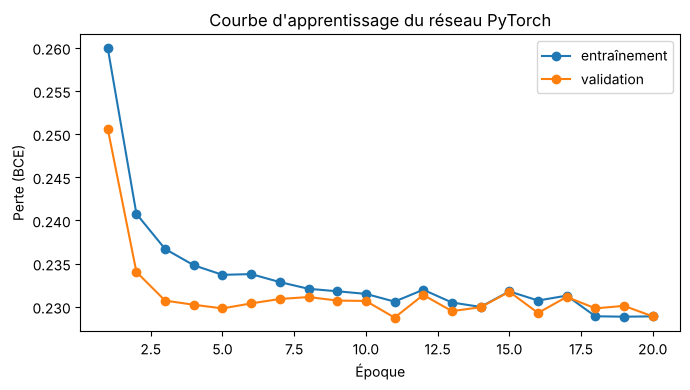

In [9]:
import matplotlib.pyplot as plt

#courbe d'apprentissage du meilleur réseau sur le 1er pli de la validation croisée
index_ent, index_eval = next(cv.split(X_train, y_train))
preparation = creer_preparation(meilleur_scaler)
X_ent = preparation.fit_transform(X_train.iloc[index_ent])
X_eval = preparation.transform(X_train.iloc[index_eval])
_, pertes = entrainer(X_ent, y_train.iloc[index_ent], X_val=X_eval, y_val=y_train.iloc[index_eval], **meilleurs_params)

plt.figure(figsize=(7, 4))
epoques = range(1, len(pertes["entraînement"]) + 1)
plt.plot(epoques, pertes["entraînement"], marker="o", label="entraînement")
plt.plot(epoques, pertes["validation"], marker="o", label="validation")
plt.xlabel("Époque")
plt.ylabel("Perte (BCE)")
plt.title("Courbe d'apprentissage du réseau PyTorch")
plt.legend()
plt.tight_layout()
plt.savefig("courbe_apprentissage_pytorch.png", dpi=150)
plt.show()

Les meilleurs réglages sont 32 puis 16 neurones, `weight_decay = 0,01` et `pos_weight = 1`. La régularisation la plus forte (0,01) est meilleure dans tous les cas, ce qui montre que le réseau a tendance à sur-apprendre sans elle. Le petit réseau (32 puis 16) fait à peine mieux que le grand (0,278 contre 0,275) : avec ces données, un réseau plus gros n'apporte rien. Comme pour XGBoost et LightGBM dans le script 1, donner plus de poids aux malades (`pos_weight = 3`) n'aide pas, on gère plutôt le déséquilibre avec le seuil.

Sur la courbe d'apprentissage, la perte baisse surtout pendant les 3 à 5 premières époques puis se stabilise. La perte de validation ne remonte pas à la fin, donc il n'y a pas de sur-apprentissage visible avec 20 époques (grâce au `weight_decay`). La courbe n'est pas parfaitement lisse (petits pics vers les époques 12 et 15), c'est dû aux mini-lots qui sont tirés au hasard.

## 7. Seuil de décision et évaluation et matrice de confusion
Comme dans le script 1, on cherche le seuil qui donne le meilleur F1, à partir des probabilités obtenues en validation croisée à l'étape 6 (le test interne n'est pas utilisé pour ça). Ensuite on entraîne le réseau sur tout l'apprentissage et on l'évalue une seule fois sur le test interne.

Métriques :
- précision : parmi les patients prédits malades, la proportion de vrais malades
- rappel : parmi les vrais malades, la proportion détectée
- F1 : moyenne harmonique de la précision et du rappel (critère du défi)
- AUC-ROC : qualité du classement des patients (0,5 = hasard, 1 = parfait)

In [10]:
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score

#on teste les seuils de 0,05 à 0,94 et on garde celui qui maximise le F1 en validation croisée
seuils_possibles = np.arange(0.05, 0.95, 0.01)
f1_par_seuil = [f1_score(y_train, proba_cv >= s) for s in seuils_possibles]
seuil = seuils_possibles[np.argmax(f1_par_seuil)]
pred_cv = proba_cv >= seuil

#entraînement sur tout l'apprentissage puis prédiction du test interne avec ce seuil
preparation = creer_preparation(meilleur_scaler)
X_train_p = preparation.fit_transform(X_train)
X_test_p = preparation.transform(X_test)
reseau, _ = entrainer(X_train_p, y_train, **meilleurs_params)
proba_test = predire_proba(reseau, X_test_p)
pred_test = proba_test >= seuil

#tableau des scores en validation croisée et sur le test interne
resultats = pd.DataFrame({
    "Validation croisée": [f1_score(y_train, pred_cv), precision_score(y_train, pred_cv),
                           recall_score(y_train, pred_cv), roc_auc_score(y_train, proba_cv)],
    "Test interne": [f1_score(y_test, pred_test), precision_score(y_test, pred_test),
                     recall_score(y_test, pred_test), roc_auc_score(y_test, proba_test)]},
    index=["F1", "Précision", "Rappel", "AUC-ROC"])

print("Seuil retenu :", round(seuil, 2))
print("Pour comparaison, F1 en validation croisée avec le seuil 0,5 :", round(f1_score(y_train, proba_cv >= 0.5), 3))
resultats.round(3)

Seuil retenu : 0.19
Pour comparaison, F1 en validation croisée avec le seuil 0,5 : 0.003


,Validation croisée,Test interne
F1,0.344,0.329
Précision,0.308,0.307
Rappel,0.391,0.354
AUC-ROC,0.776,0.768


In [11]:
from sklearn.metrics import confusion_matrix

#matrice de confusion du réseau sur le test interne (réseau entraîné sur l'apprentissage seulement)
vn, fp, fn, vp = confusion_matrix(y_test, pred_test).ravel()

print("VP (malades détectés) =", vp, "| FN (malades ratés) =", fn)
print("FP (fausses alertes) =", fp, "| VN (non malades bien classés) =", vn)
#indicateurs cliniques
print("Sensibilité :", round(vp / (vp + fn), 3), "| Spécificité :", round(vn / (vn + fp), 3),
      "| VPP :", round(vp / (vp + fp), 3), "| VPN :", round(vn / (vn + fn), 3))

VP (malades détectés) = 67 | FN (malades ratés) = 122
FP (fausses alertes) = 151 | VN (non malades bien classés) = 2011
Sensibilité : 0.354 | Spécificité : 0.93 | VPP : 0.307 | VPN : 0.943


Le seuil retenu est 0,19. Avec le seuil de 0,5 le F1 tombe à 0,003 : presque aucun vrai malade n'a une probabilité au-dessus de 0,5, le réseau ne détecterait donc quasiment aucun malade. Ça confirme qu'il faut baisser le seuil.

Le F1 est de 0,344 en validation croisée et 0,329 sur le test interne. Les deux sont proches, donc l'estimation est fiable. Sur le test, le réseau détecte environ un tiers des malades (rappel 0,35), et environ 3 alertes sur 10 sont de vrais malades (précision 0,31).

L'ordre scaler puis imputation (étape 5) compte beaucoup pour le réseau : avec l'ordre inverse, les colonnes "manquant oui/non" valaient -5,2 et +5,2 et le réseau ne faisait que 0,318 en validation croisée et 0,310 sur le test.

Le réseau fait aussi bien que les meilleurs modèles seuls du script 1 (F1 en validation croisée : régression logistique 0,343, LightGBM 0,343, random forest 0,346), mais un peu moins bien que le Super Learner (0,360), qui combine des modèles de familles différentes. Ce n'est pas très étonnant : sur des données tabulaires avec seulement 11 753 patients, un réseau de neurones n'apporte pas d'avantage par rapport aux modèles classiques. 

## 8. Réseau final et prédiction du fichier de test
- On réentraîne le réseau sur les 11 753 patients avec les meilleurs réglages (la préparation est aussi réapprise sur tous les patients).
- On lit le fichier de test, on applique le même nettoyage et la même préparation, puis on prédit 0 ou 1 avec le seuil de 0,19.
- On enregistre un fichier csv avec 2 colonnes `ID` et `pred`.


In [12]:
#réseau final : préparation + réseau réappris sur tous les patients
preparation_finale = creer_preparation(meilleur_scaler)
X_tout_p = preparation_finale.fit_transform(X)
reseau_final, _ = entrainer(X_tout_p, y, **meilleurs_params)

#lecture du fichier à prédire et même nettoyage
df_test = nettoyer(pd.read_csv(fichier_test))

#mêmes variables dans le même ordre, puis même préparation
X_nouveau = preparation_finale.transform(df_test.reindex(columns=X.columns))

#probabilité puis décision 0/1 avec le seuil
prediction = (predire_proba(reseau_final, X_nouveau) >= seuil).astype(int)

#identifiants : colonne ID si elle existe, sinon 1, 2, 3...
if "ID" in df_test:
    ids = df_test["ID"]
else:
    ids = np.arange(1, len(df_test) + 1)

#fichier de prédictions : ID et pred
pd.DataFrame({"ID": ids, "pred": prediction}).to_csv(fichier_sortie, index=False)
print("Fichier prédit :", fichier_test)
print(len(df_test), "patients prédits dont", prediction.sum(), "bactériémies | fichier créé :", fichier_sortie)

Fichier prédit : bacteriemie_test.csv.gz
2938 patients prédits dont 268 bactériémies | fichier créé : groupe4_ABAKAR_ASAS_SAAD_SOYLU_BOUGHANEM_MOUYANSELE_pytorch.csv
